ARTI308 - Machine Learning

# Project Notebook 1: Exploratory Data Analysis (EDA)
## Heart Disease Prediction

**Goal of the project:** build a classification model that predicts whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0) from clinical measurements.

**Goal of this notebook:** understand the raw data *before* touching it. We do not change anything here; we only look.

### Dataset
Heart Failure Prediction Dataset (Kaggle, author: fedesoriano) - 918 patients, 11 input features and 1 target.
Check the license on the dataset's Kaggle page and cite it in the README.

| Column | Meaning |
|---|---|
| Age | age of the patient (years) |
| Sex | M / F |
| ChestPainType | TA, ATA, NAP, ASY |
| RestingBP | resting blood pressure (mm Hg) |
| Cholesterol | serum cholesterol (mg/dl) |
| FastingBS | 1 if fasting blood sugar > 120 mg/dl, else 0 |
| RestingECG | Normal, ST, LVH |
| MaxHR | maximum heart rate achieved |
| ExerciseAngina | exercise-induced angina (Y / N) |
| Oldpeak | ST depression induced by exercise |
| ST_Slope | slope of the peak exercise ST segment (Up, Flat, Down) |
| HeartDisease | **target**: 1 = heart disease, 0 = normal |

## 1. Setup and imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load the dataset

In [2]:
# Path relative to this notebook (notebooks/ -> data/raw/)
DATA_PATH = "../data/raw/heart.csv"

# On Google Colab you can read the raw file directly from GitHub instead:
# DATA_PATH = "https://raw.githubusercontent.com/<username>/Heart-Disease-Prediction/main/data/raw/heart.csv"

df = pd.read_csv(DATA_PATH)
df.head(7)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0


**Observation:**

The table displays the first 7 patient records with clinical features (such as `Age`, `Sex`, `ChestPainType`, `RestingBP`, `Cholesterol`, `MaxHR`, `ExerciseAngina`, `Oldpeak`, and `ST_Slope`) along with the target label `HeartDisease` (0 or 1).

## 3. Quick dataset checks
### 3.1 Shape

In [3]:
print("Shape (rows, columns):", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Shape (rows, columns): (918, 12)
Number of rows: 918
Number of columns: 12


**Observation:**

The dataset contains **918 rows** (patients) and **12 columns** (11 input features plus the target column `HeartDisease`).

### 3.2 Data types
Each column's type should match its real meaning (numbers as numbers, categories as text).

In [4]:
df.dtypes

Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

**Observation:**

Column data types match their real meanings: numerical columns are integers (`int64`) or floats (`float64`), while categorical columns are strings/text (`str` / `object`), so no type casting is required here.

### 3.3 Missing values (the obvious kind)
`isna()` only finds values that are literally empty (`NaN`).

In [5]:
df.isna().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

**Observation:**

There are **0** explicit missing values (`NaN`) across all columns, though hidden missing values may still be encoded as invalid numbers such as zeros.

### 3.4 Duplicate rows

In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


**Observation:**

There are **0** duplicate rows in the raw dataset.

### 3.5 Descriptive statistics
`include="all"` shows numerical and categorical columns together. Pay attention to the `min` row.

In [7]:
df.describe(include="all")

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
count,918.000000,918,918,918.000000,918.000000,918.000000,918,918.000000,918,918.000000,918,918.000000
unique,NaN,2,4,NaN,NaN,NaN,3,NaN,2,NaN,3,NaN
top,NaN,M,ASY,NaN,NaN,NaN,Normal,NaN,N,NaN,Flat,NaN
freq,NaN,725,496,NaN,NaN,NaN,552,NaN,547,NaN,460,NaN
mean,53.510893,NaN,NaN,132.396514,198.799564,0.233115,NaN,136.809368,NaN,0.887364,NaN,0.553377
std,9.432617,NaN,NaN,18.514154,109.384145,0.423046,NaN,25.460334,NaN,1.066570,NaN,0.497414
min,28.000000,NaN,NaN,0.000000,0.000000,0.000000,NaN,60.000000,NaN,-2.600000,NaN,0.000000
25%,47.000000,NaN,NaN,120.000000,173.250000,0.000000,NaN,120.000000,NaN,0.000000,NaN,0.000000
50%,54.000000,NaN,NaN,130.000000,223.000000,0.000000,NaN,138.000000,NaN,0.600000,NaN,1.000000
75%,60.000000,NaN,NaN,140.000000,267.000000,0.000000,NaN,156.000000,NaN,1.500000,NaN,1.000000


**Observation:**

The `min` row reveals `0.0` in `RestingBP` and `Cholesterol` as well as `-2.6` in `Oldpeak`, alongside wide differences in scale and spread (`std`) across numerical features.

### 3.6 Hidden problems
`isna()` can say "no missing values" while the data still contains **impossible values** that were used as a placeholder.
A resting blood pressure of 0 or a cholesterol of 0 is not physically possible for a living patient.
We also check `Oldpeak` for negative values.

In [8]:
print("Zeros in RestingBP:   ", (df["RestingBP"] == 0).sum())
print("Zeros in Cholesterol: ", (df["Cholesterol"] == 0).sum())
print("Negative Oldpeak:     ", (df["Oldpeak"] < 0).sum())

Zeros in RestingBP:    1
Zeros in Cholesterol:  172
Negative Oldpeak:      13


**Observation:**

Despite `isna()` reporting zero missing values, there is **1** zero in `RestingBP` and **172** zeros in `Cholesterol` (physically impossible placeholders for missing measurements), plus **13** negative values in `Oldpeak`.

## 4. Target variable and class balance
If one class dominates, accuracy alone can be misleading.

In [9]:
target_col = "HeartDisease"
print(df[target_col].value_counts())
print()
print(df[target_col].value_counts(normalize=True).round(3))

HeartDisease
1    508
0    410
Name: count, dtype: int64

HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64


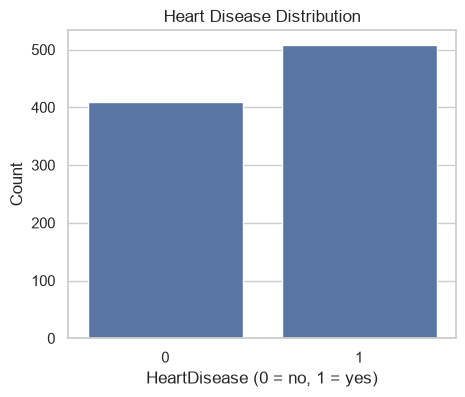

In [10]:
plt.figure(figsize=(5, 4))
sns.countplot(x=target_col, data=df)
plt.title("Heart Disease Distribution")
plt.xlabel("HeartDisease (0 = no, 1 = yes)")
plt.ylabel("Count")
plt.show()

**Observation:**

`HeartDisease = 1` accounts for **508 patients (55.3%)** and `HeartDisease = 0` accounts for **410 patients (44.7%)**, indicating a fairly balanced target with a slight majority in the positive class.

## 5. Feature types

In [11]:
numeric_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
binary_cols = ["FastingBS"]
categorical_cols = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

print("Numeric:    ", numeric_cols)
print("Binary:     ", binary_cols)
print("Categorical:", categorical_cols)

Numeric:     ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
Binary:      ['FastingBS']
Categorical: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


Numeric columns are measured quantities; categorical columns hold text labels that must be **encoded** before modeling (done in the model notebooks).

## 6. Univariate analysis
### 6.1 Numeric features
Look at the shape of each histogram: symmetric, skewed, more than one peak?

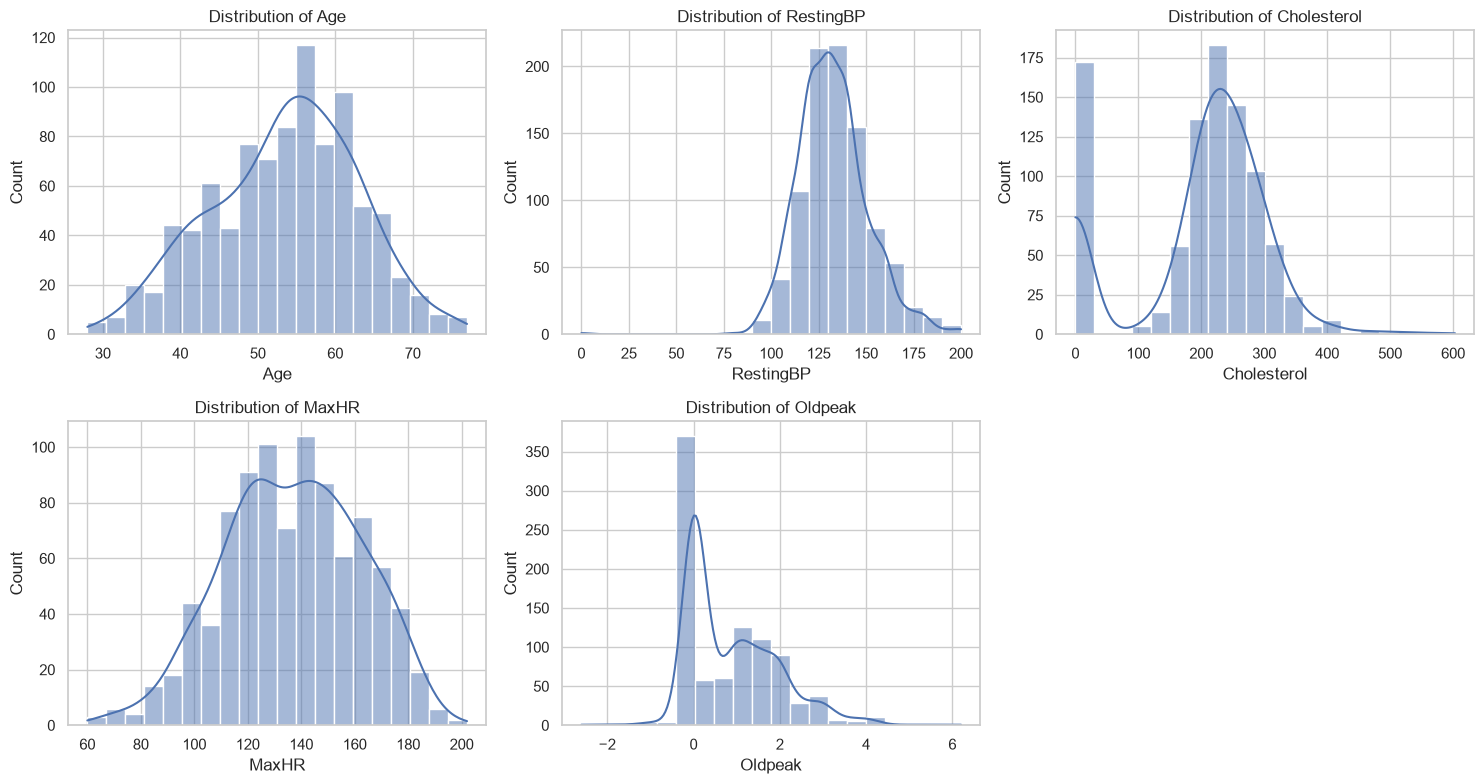

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.histplot(df[col], bins=20, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

**Observation:**

`Age` and `MaxHR` are fairly close to symmetric/bell-shaped distributions, whereas `Cholesterol` and `RestingBP` show spikes at zero and `Oldpeak` is positively skewed.

### 6.2 Categorical features

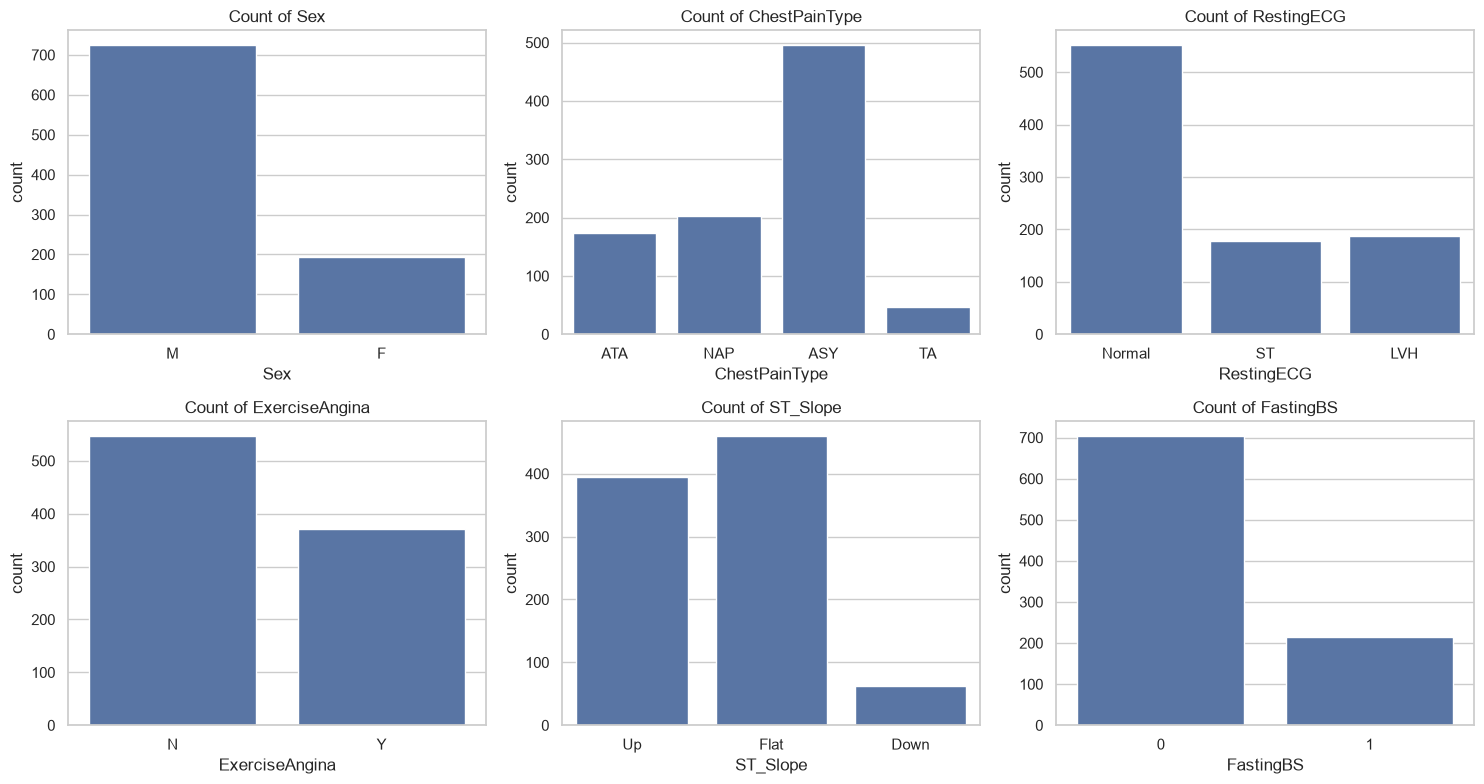

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), categorical_cols + binary_cols):
    sns.countplot(x=col, data=df, ax=ax)
    ax.set_title(f"Count of {col}")
plt.tight_layout()
plt.show()

**Observation:**

Dominant categories include `M` in `Sex`, `ASY` in `ChestPainType`, `Normal` in `RestingECG`, `N` in `ExerciseAngina`, `Flat` in `ST_Slope`, and `0` in `FastingBS`.

## 7. Bivariate analysis (features vs. target)
### 7.1 Numeric features vs. HeartDisease
Box plots: compare the median and spread of each feature for patients with and without heart disease.

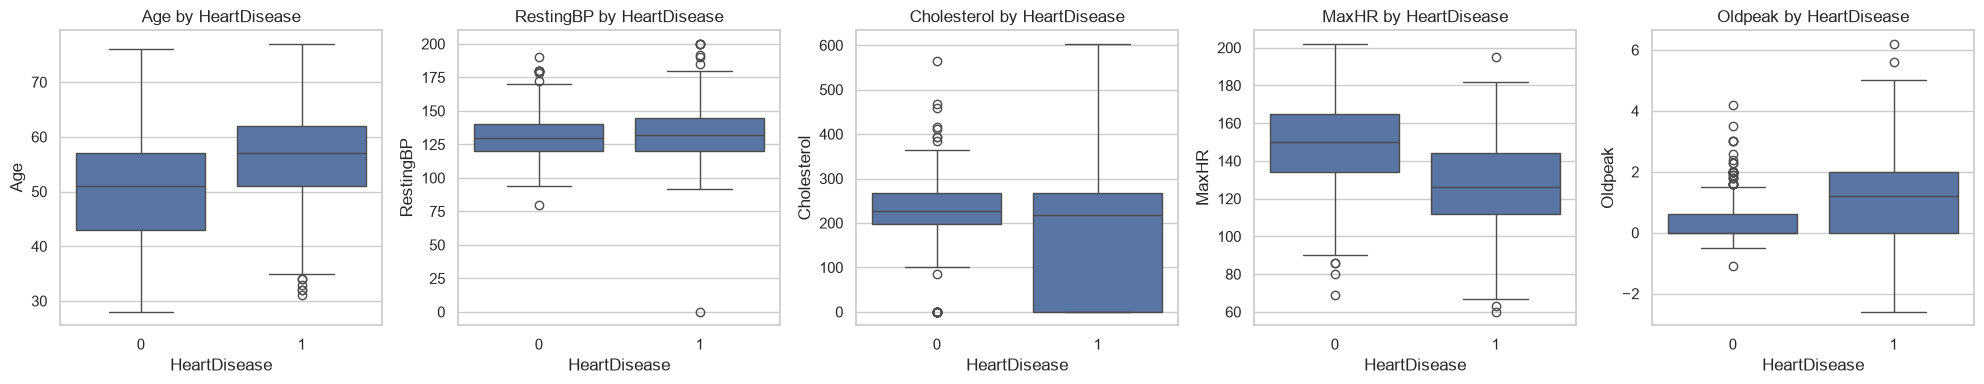

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x=target_col, y=col, data=df, ax=ax)
    ax.set_title(f"{col} by HeartDisease")
plt.tight_layout()
plt.show()

**Observation:**

Patients with heart disease (`HeartDisease = 1`) tend to have a higher median `Age` and `Oldpeak`, while their median `MaxHR` is noticeably lower than in patients without heart disease (`0`).

### 7.2 Categorical features vs. HeartDisease
This is a **grouped bar chart**: each category has one bar per class, side by side.

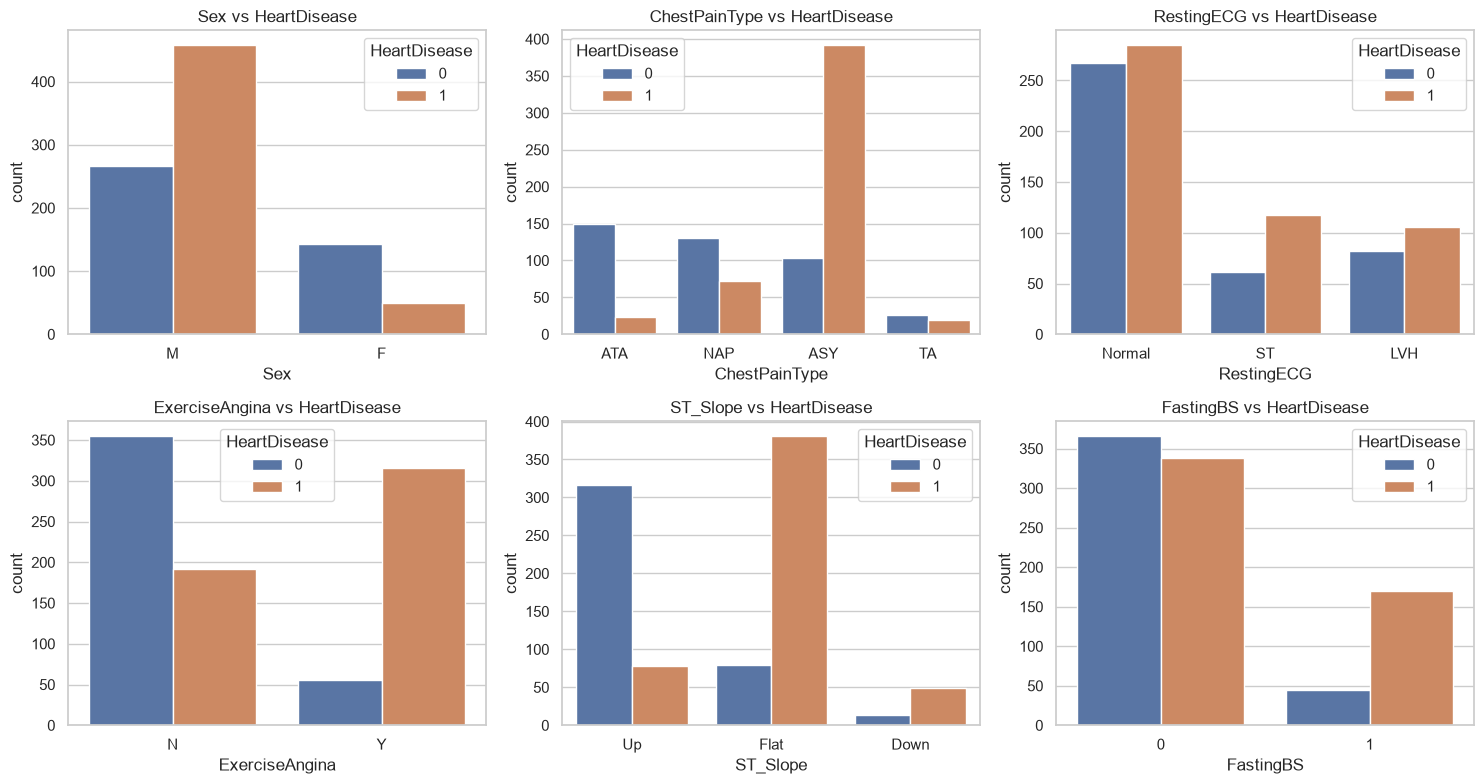

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), categorical_cols + binary_cols):
    sns.countplot(x=col, hue=target_col, data=df, ax=ax)
    ax.set_title(f"{col} vs HeartDisease")
plt.tight_layout()
plt.show()

**Observation:**

Higher counts and proportions of heart disease (`HeartDisease = 1`) appear notably in `ST_Slope = Flat` or `Down`, `ExerciseAngina = Y`, `ChestPainType = ASY`, `Sex = M`, and `FastingBS = 1`.


Counts can be misleading when categories have different sizes, so we also compute the **percentage** of patients with heart disease inside each category.

In [16]:
for col in categorical_cols + binary_cols:
    print(f"--- {col} ---")
    print(df.groupby(col)[target_col].mean().round(3).sort_values(ascending=False))
    print()

--- Sex ---
Sex
M    0.632
F    0.259
Name: HeartDisease, dtype: float64

--- ChestPainType ---
ChestPainType
ASY    0.790
TA     0.435
NAP    0.355
ATA    0.139
Name: HeartDisease, dtype: float64

--- RestingECG ---
RestingECG
ST        0.657
LVH       0.564
Normal    0.516
Name: HeartDisease, dtype: float64

--- ExerciseAngina ---
ExerciseAngina
Y    0.852
N    0.351
Name: HeartDisease, dtype: float64

--- ST_Slope ---
ST_Slope
Flat    0.828
Down    0.778
Up      0.197
Name: HeartDisease, dtype: float64

--- FastingBS ---
FastingBS
1    0.794
0    0.480
Name: HeartDisease, dtype: float64



**Observation:**

Proportions confirm strong risk differences across categories: heart disease rates are highest in `ExerciseAngina = Y` (**0.852**), `ST_Slope = Flat` (**0.828**) and `Down` (**0.778**), `FastingBS = 1` (**0.794**), `ChestPainType = ASY` (**0.790**), `RestingECG = ST` (**0.657**), and `Sex = M` (**0.632**).

### 7.3 Are the zero cholesterol values random?
If the zeros were random, they would be spread evenly over both classes. Compare below.

In [17]:
df["Cholesterol_is_zero"] = (df["Cholesterol"] == 0).astype(int)
print(pd.crosstab(df["Cholesterol_is_zero"], df[target_col]))
print()
print(pd.crosstab(df["Cholesterol_is_zero"], df[target_col], normalize="index").round(3))
df = df.drop(columns="Cholesterol_is_zero")   # temporary helper column

HeartDisease           0    1
Cholesterol_is_zero          
0                    390  356
1                     20  152

HeartDisease             0      1
Cholesterol_is_zero              
0                    0.523  0.477
1                    0.116  0.884


**Observation:**

Zero-cholesterol rows (`Cholesterol_is_zero = 1`, 172 rows) are not spread evenly across classes: **88.4%** (`152` rows) belong to `HeartDisease = 1` versus **11.6%** (`20` rows) in `HeartDisease = 0`, compared with **47.7%** vs. **52.3%** when cholesterol is non-zero (`0`). Thus, the zeros are not purely random and are strongly concentrated in heart disease cases.

## 8. Correlation
Correlation measures the *linear* relationship between numeric variables (-1 to +1). The diagonal is always 1.

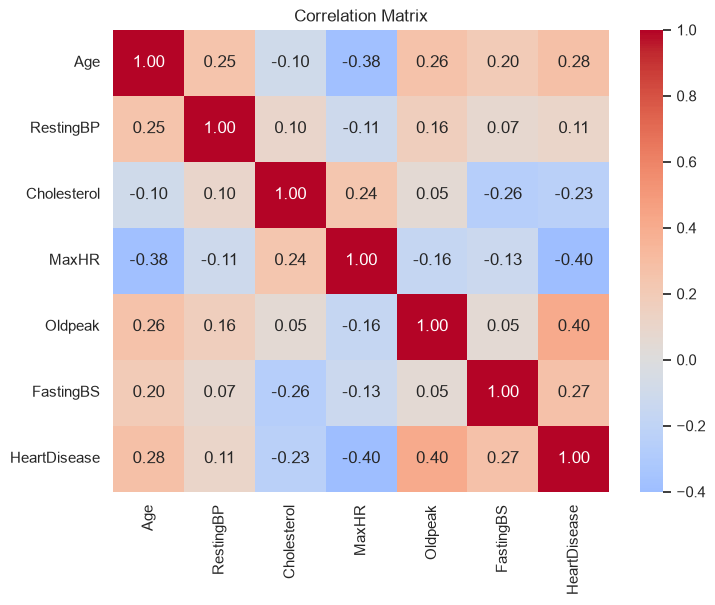

In [18]:
corr_cols = numeric_cols + binary_cols + [target_col]
plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

**Observation:**

Linear correlations with `HeartDisease` are moderate to weak, with positive correlation for `Oldpeak` (`0.40`), `Age` (`0.28`), and `FastingBS` (`0.27`), and negative correlation for `MaxHR` (`-0.40`) and `Cholesterol` (`-0.23`).

## Summary of issues found (fill this in)

List the data-quality problems you found in this notebook. They will be fixed in **notebook 2 (preprocessing)**.

1. Hidden missing values coded as impossible `0` entries in `Cholesterol` (172 rows) and `RestingBP` (1 row) that `isna()` does not detect.
2. 13 negative values in `Oldpeak` that require inspection and a documented handling decision.
3. Differing feature scales and extreme/outlier values that should be handled carefully inside a `Pipeline` after splitting to prevent data leakage.

---
### Task
Use `groupby` to compute the mean `Age` and mean `MaxHR` for each value of `HeartDisease`, and explain the difference in one sentence.

In [19]:
print(df.groupby("HeartDisease")[["Age", "MaxHR"]].mean().round(2))

                Age   MaxHR
HeartDisease               
0             50.55  148.15
1             55.90  127.66


Patients with heart disease (`HeartDisease = 1`) are on average older (`55.90` vs. `50.55` years) and achieve a lower maximum heart rate (`127.66` vs. `148.15` bpm) than those without heart disease (`HeartDisease = 0`).